# CS01: RFM scoring and KMeans segmentation (Online Retail II)

Snapshot date: 2011-06-01. Only transactions before the snapshot are used.
Cancelled invoices, missing customer IDs and non-positive quantity/price rows are removed.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples

from rfmseg.core import (
    RANDOM_STATE,
    SNAPSHOT_DATE,
    cluster_metrics,
    data_path,
    fit_kmeans,
    load_retail,
    rfm_features,
    scale_features,
    segment_profile,
    segment_sizes,
)

FIG = Path.cwd().parent / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
MIN_SHARE = 0.02

In [2]:
tx = load_retail()
print("data:", data_path())
print("transactions after cleaning:", len(tx), "| range:", tx.InvoiceDate.min(), "to", tx.InvoiceDate.max())

feats = rfm_features(tx, SNAPSHOT_DATE)
X = scale_features(feats)
print("customers with history at snapshot:", len(feats))
feats.describe().round(2)

data: /home/patotricks15/.local/share/clv-data/online-retail-ii/online_retail_II.csv
transactions after cleaning: 805549 | range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


customers with history at snapshot: 4933


,recency_days,frequency,monetary,tenure_days,monetary_90d,avg_order_value
count,4933.00,4933.00,4933.00,4933.00,4933.00,4933.00
mean,168.71,5.24,1984.89,357.19,336.09,380.58
std,141.93,10.13,3613.92,154.49,1286.40,521.76
min,0.00,1.00,2.90,0.00,0.00,2.90
25%,43.00,1.00,317.60,232.00,0.00,181.84
50%,161.00,3.00,774.87,392.00,0.00,289.90
75%,243.00,6.00,2001.07,490.00,307.53,426.43
max,546.00,258.00,25233.80,546.00,25233.80,14844.77


In [3]:
rows = []
models = {}
for k in range(3, 9):
    model, labels = fit_kmeans(X, k)
    models[k] = labels
    m = cluster_metrics(X, labels)
    m["k"] = k
    m["min_segment_share"] = segment_sizes(labels).min()
    rows.append(m)
sweep = pd.DataFrame(rows).set_index("k").round(4)
sweep

,silhouette,davies_bouldin,calinski_harabasz,min_segment_share
k,,,,
3,0.3591,1.0303,2388.7097,0.1091
4,0.2986,1.0721,2382.3103,0.0999
5,0.2821,1.1564,2152.0689,0.0975
6,0.2496,1.2332,2002.5414,0.0957
7,0.2602,1.1348,1924.1130,0.0843
8,0.2557,1.1660,1854.0608,0.0257


In [4]:
best_k = int(sweep["silhouette"].idxmax())
sweep_ok = sweep[sweep["min_segment_share"] >= MIN_SHARE]
print("best k by silhouette:", best_k)
print("k values where all segments reach the 2% minimum:", list(sweep_ok.index))
labels = models[best_k]
print("metrics at chosen k:", {k: round(v, 3) for k, v in cluster_metrics(X, labels).items()})

best k by silhouette: 3
k values where all segments reach the 2% minimum: [3, 4, 5, 6, 7, 8]


metrics at chosen k: {'silhouette': 0.359, 'davies_bouldin': 1.03, 'calinski_harabasz': 2388.71}


In [5]:
profile = segment_profile(feats, labels)
profile.round(2)

,customers,median_recency_days,median_frequency,median_monetary,share
segment,,,,,
0,1594,28.0,8.0,3056.62,0.32
1,2801,228.0,2.0,454.66,0.57
2,538,46.0,1.0,331.52,0.11


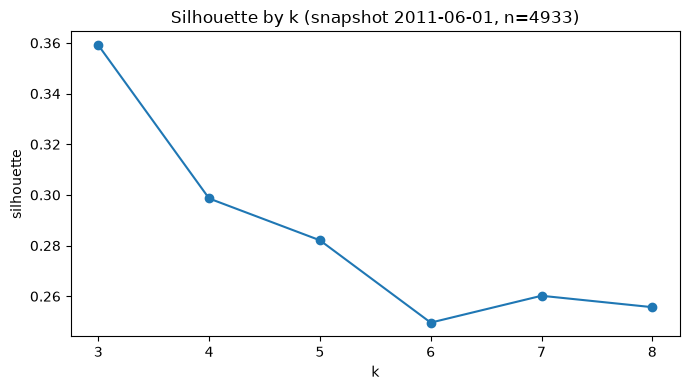

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sweep[["silhouette"]].plot(ax=ax, marker="o", legend=False)
ax.set_title(f"Silhouette by k (snapshot {SNAPSHOT_DATE.date()}, n={len(X)})")
ax.set_ylabel("silhouette")
fig.tight_layout()
fig.savefig(FIG / "cs01_silhouette_by_k.png", dpi=120)
plt.show()

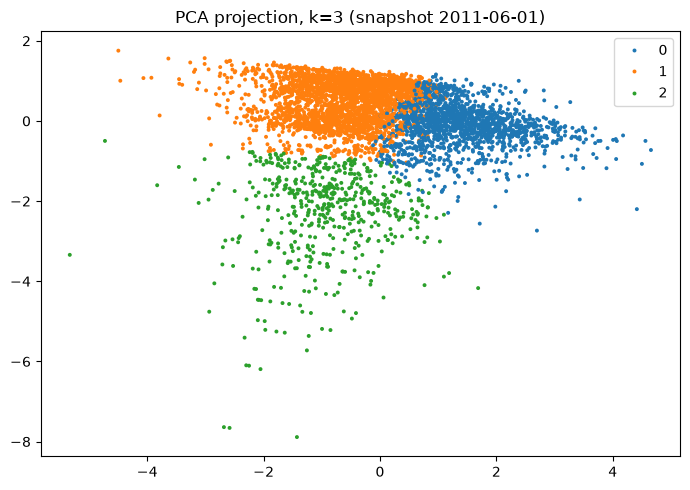

In [7]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=pca[:, 0], y=pca[:, 1], hue=labels, palette="tab10", s=8, linewidth=0, ax=ax)
ax.set_title(f"PCA projection, k={best_k} (snapshot {SNAPSHOT_DATE.date()})")
fig.tight_layout()
fig.savefig(FIG / "cs01_pca.png", dpi=120)
plt.show()

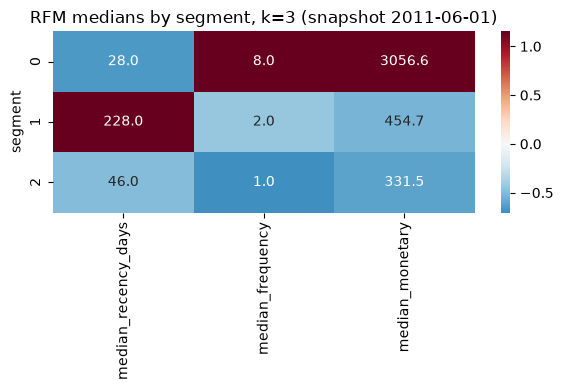

In [8]:
heat = profile[["median_recency_days", "median_frequency", "median_monetary"]]
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap((heat - heat.mean()) / heat.std(), annot=heat.round(1), fmt="", cmap="RdBu_r", center=0, ax=ax)
ax.set_title(f"RFM medians by segment, k={best_k} (snapshot {SNAPSHOT_DATE.date()})")
fig.tight_layout()
fig.savefig(FIG / "cs01_rfm_heatmap.png", dpi=120)
plt.show()

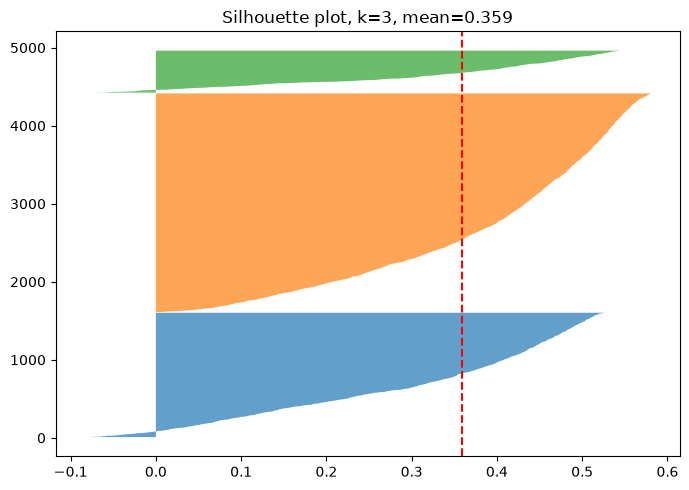

In [9]:
sil = silhouette_samples(X, labels)
fig, ax = plt.subplots(figsize=(7, 5))
y_lower = 10
for c in range(best_k):
    vals = np.sort(sil[labels == c])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.7)
    y_lower = y_upper + 10
ax.axvline(sil.mean(), color="red", linestyle="--")
ax.set_title(f"Silhouette plot, k={best_k}, mean={sil.mean():.3f}")
fig.tight_layout()
fig.savefig(FIG / "cs01_silhouette_plot.png", dpi=120)
plt.show()

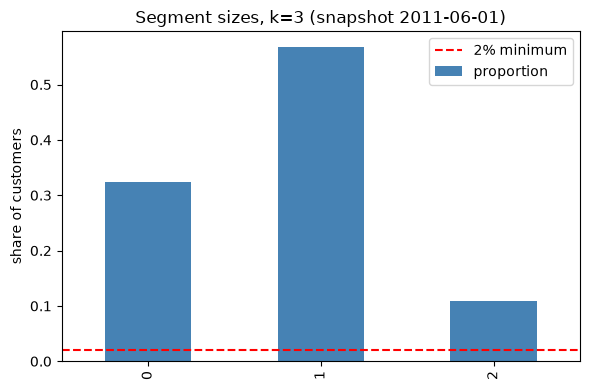

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
segment_sizes(labels).plot.bar(ax=ax, color="steelblue")
ax.axhline(MIN_SHARE, color="red", linestyle="--", label="2% minimum")
ax.set_ylabel("share of customers")
ax.set_title(f"Segment sizes, k={best_k} (snapshot {SNAPSHOT_DATE.date()})")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "cs01_segment_sizes.png", dpi=120)
plt.show()